In [1]:

!pip -q install gradio scikit-learn seaborn

import os
import zipfile
import urllib.request

url = "https://github.com/Ebuka24Stephen/trashnet-dataset/archive/refs/heads/main.zip"

urllib.request.urlretrieve(url, "/content/trashnet.zip")

with zipfile.ZipFile("/content/trashnet.zip", "r") as z:
    z.extractall("/content/")

DATA_DIR = "/content/trashnet-dataset-main"

print("Dataset downloaded successfully!")
print("Folders:", os.listdir(DATA_DIR))


Dataset downloaded successfully!
Folders: ['glass', 'trash', 'cardboard', 'plastic', 'README.md', 'paper', '.gitignore', 'metal']


In [2]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

from PIL import Image
import glob

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

CLASSES = [
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
]

paths = []
labels = []

for index, category in enumerate(CLASSES):
    files = glob.glob(
        os.path.join(DATA_DIR, category, "*")
    )
    files = [f for f in files if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )]

    paths.extend(files)
    labels.extend([index] * len(files))

paths = np.array(paths)
labels = np.array(labels)

train_paths, temp_paths, train_labels, temp_labels = (
    train_test_split(
        paths, labels,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )
)

val_paths, test_paths, val_labels, test_labels = (
    train_test_split(
        temp_paths, temp_labels,
        test_size=0.50,
        stratify=temp_labels,
        random_state=SEED
    )
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )
    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(1000, seed=SEED)

    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )

train_ds = make_dataset(
    train_paths, train_labels, True
)

val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Classes:", CLASSES)


Training images: 1768
Validation images: 379
Testing images: 380
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [3]:

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),

    layers.Conv2D(32, (3, 3), activation="relu",
                  padding="same", name="conv1"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu",
                  padding="same", name="conv2"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu",
                  padding="same", name="conv3"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), activation="relu",
                  padding="same", name="last_conv"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [4]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "smartwaste_best.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("CNN training completed!")


Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 78ms/step - accuracy: 0.4525 - loss: 1.4805 - val_accuracy: 0.2216 - val_loss: 1.7674 - learning_rate: 0.0010
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.5294 - loss: 1.2245 - val_accuracy: 0.1135 - val_loss: 1.9112 - learning_rate: 0.0010
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.5962 - loss: 1.1158 - val_accuracy: 0.1161 - val_loss: 2.3448 - learning_rate: 0.0010
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.6244 - loss: 1.0245 - val_accuracy: 0.2058 - val_loss: 2.2994 - learning_rate: 5.0000e-04
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.6686 - loss: 0.9441 - val_accuracy: 0.2243 - val_loss: 2.3844 - learning_rate: 5.0000e-04
CNN training completed!


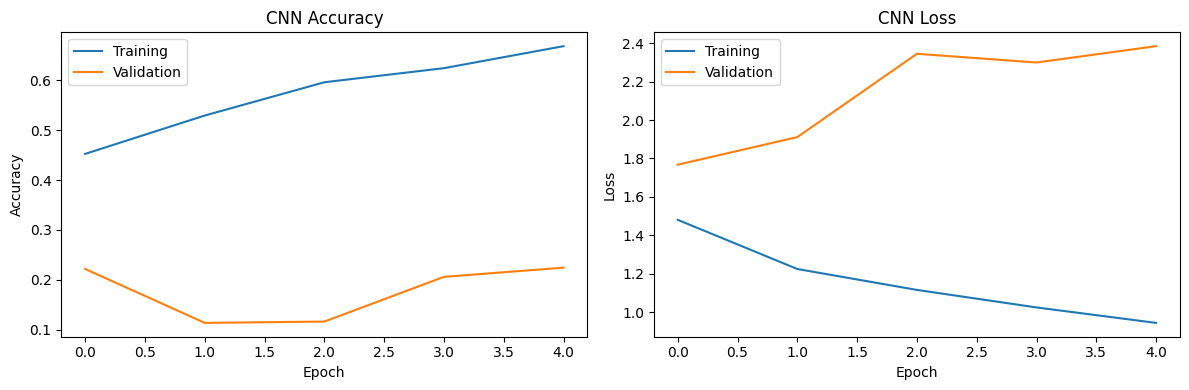

In [5]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.2342 - loss: 1.7560
Test Accuracy: 23.42%
Test Loss: 1.7560
              precision    recall  f1-score   support

   cardboard       0.00      0.00      0.00        60
       glass       0.08      0.03      0.04        76
       metal       0.00      0.00      0.00        62
       paper       0.24      0.98      0.39        89
     plastic       0.00      0.00      0.00        73
       trash       0.00      0.00      0.00        20

    accuracy                           0.23       380
   macro avg       0.05      0.17      0.07       380
weighted avg       0.07      0.23      0.10       380



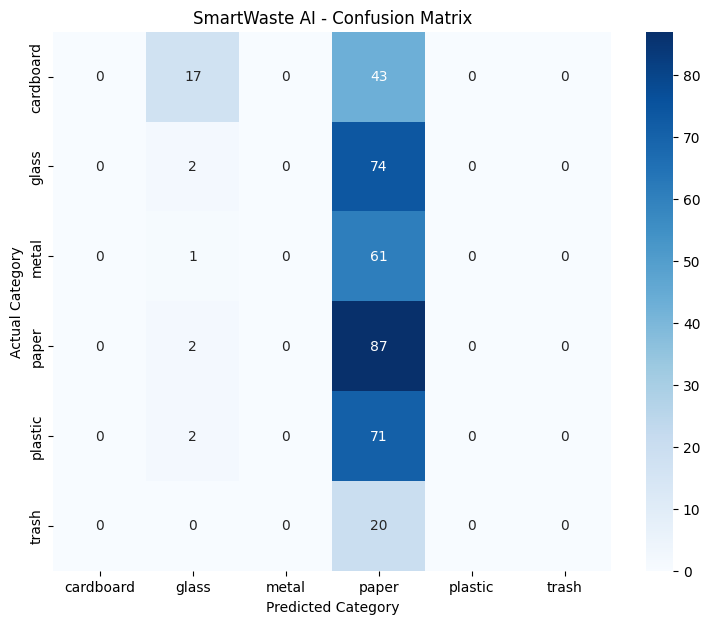

In [6]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

y_true = []
y_pred = []

for images, labels_batch in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels_batch.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - Confusion Matrix")
plt.show()


In [7]:
# CELL 7: Grad-CAM Explainable AI (FIXED)

import tensorflow as tf
import numpy as np

# Explicitly build/call the CNN model
dummy_input = tf.zeros((1, 128, 128, 3))
_ = model(dummy_input, training=False)

# Create Grad-CAM model
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("last_conv").output,
        model.outputs[0]
    ]
)

def make_gradcam(image_array):

    image_array = tf.convert_to_tensor(
        image_array, dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_output, predictions = grad_model(
            image_array, training=False
        )

        class_index = tf.argmax(predictions[0])

        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_output[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / tf.maximum(
        tf.reduce_max(heatmap), 1e-8
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE
    ).numpy().squeeze()

    return heatmap

print("Grad-CAM explanation module ready!")

Grad-CAM explanation module ready!


In [8]:

RECYCLING_GUIDE = {
    "cardboard": "Keep dry, flatten boxes and send for paper recycling.",
    "glass": "Separate by glass type and send to an appropriate glass recycler.",
    "metal": "Clean cans and containers before metal recycling.",
    "paper": "Keep paper clean and dry for paper recycling.",
    "plastic": "Check local recycling rules and separate accepted plastics.",
    "trash": "Place in general waste unless a specialized recycling facility accepts it."
}

def predict_waste(image):
    if image is None:
        raise gr.Error("Please upload an image.")

    image = image.convert("RGB")
    original = image.resize(IMG_SIZE)

    arr = np.array(original).astype("float32") / 255.0
    batch = np.expand_dims(arr, axis=0)

    predictions = model.predict(batch, verbose=0)[0]

    index = int(np.argmax(predictions))
    category = CLASSES[index]
    confidence = float(predictions[index])

    result = {
        CLASSES[i]: float(predictions[i])
        for i in range(len(CLASSES))
    }

    heatmap = make_gradcam(batch)

    heatmap_img = Image.fromarray(
        np.uint8(heatmap * 255)
    ).resize(IMG_SIZE)

    import cv2

    heat = cv2.applyColorMap(
        np.array(heatmap_img), cv2.COLORMAP_JET
    )
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)

    original_array = np.array(original)
    overlay = (
        0.55 * original_array +
        0.45 * heat
    ).clip(0, 255).astype("uint8")

    explanation = (
        f"Predicted Category: {category.upper()}\n"
        f"Confidence: {confidence * 100:.2f}%\n\n"
        f"Recycling Guidance:\n{RECYCLING_GUIDE[category]}\n\n"
        "Note: This is an educational model, not a "
        "certified waste-disposal system."
    )

    return result, explanation, Image.fromarray(overlay)

demo = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(
        type="pil",
        label="Upload Waste Image"
    ),
    outputs=[
        gr.Label(num_top_classes=6, label="CNN Predictions"),
        gr.Textbox(label="AI Recycling Assistant"),
        gr.Image(label="Grad-CAM Explanation")
    ],
    title="♻️ SmartWaste AI",
    description=(
        "CNN-powered intelligent waste classification "
        "with explainable AI and recycling guidance."
    ),
    examples=None
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6fd843640dcc10d44a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [9]:
print("========== SMARTWASTE AI DIAGNOSTICS ==========")

# 1. Check dataset distribution
print("\nDATASET DISTRIBUTION:")

for i, name in enumerate(CLASSES):
    print(name, ":", np.sum(train_labels == i))

# 2. Check model accuracy
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print("\nMODEL PERFORMANCE:")
print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Testing Accuracy: {test_acc*100:.2f}%")

# 3. Check prediction distribution
predictions = model.predict(test_ds, verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

print("\nPREDICTION DISTRIBUTION:")

for i, name in enumerate(CLASSES):
    print(name, ":", np.sum(predicted_labels == i))

# 4. Check class mapping
print("\nCLASS MAPPING:")
for i, name in enumerate(CLASSES):
    print(i, "=", name)

print("\n========== DIAGNOSTICS COMPLETE ==========")

========== SMARTWASTE AI DIAGNOSTICS ==========

DATASET DISTRIBUTION:
cardboard : 282
glass : 350
metal : 287
paper : 416
plastic : 337
trash : 96

MODEL PERFORMANCE:
Training Accuracy: 23.36%
Validation Accuracy: 22.16%
Testing Accuracy: 23.42%

PREDICTION DISTRIBUTION:
cardboard : 0
glass : 24
metal : 0
paper : 356
plastic : 0
trash : 0

CLASS MAPPING:
0 = cardboard
1 = glass
2 = metal
3 = paper
4 = plastic
5 = trash

========== DIAGNOSTICS COMPLETE ==========


In [10]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = {
    int(i): float(w)
    for i, w in enumerate(weights)
}

print("CLASS WEIGHTS")

for i, name in enumerate(CLASSES):
    print(name, ":", round(class_weights[i], 3))

CLASS WEIGHTS
cardboard : 1.045
glass : 0.842
metal : 1.027
paper : 0.708
plastic : 0.874
trash : 3.069


In [11]:
# SMARTWASTE AI - IMPROVED TRAINING

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "smartwaste_improved.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_improved = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)

print("Improved CNN training completed!")

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.5277 - loss: 1.2862 - val_accuracy: 0.1979 - val_loss: 1.8722 - learning_rate: 2.5000e-04
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.5837 - loss: 1.1390 - val_accuracy: 0.1979 - val_loss: 2.0663 - learning_rate: 2.5000e-04
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.5871 - loss: 1.0916 - val_accuracy: 0.2559 - val_loss: 2.1083 - learning_rate: 2.5000e-04
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.6227 - loss: 1.0301 - val_accuracy: 0.2375 - val_loss: 2.0519 - learning_rate: 1.2500e-04
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.6459 - loss: 0.9773 - val_accuracy: 0.2533 - val_loss: 1.9006 - learning_rate: 1.2500e-04
Improved CNN training completed!


In [12]:
test_loss, test_accuracy = model.evaluate(
    test_ds, verbose=0
)

print(
    f"Improved Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

y_true = []
y_pred = []

for images, labels_batch in test_ds:
    probs = model.predict(images, verbose=0)

    y_true.extend(labels_batch.numpy())
    y_pred.extend(np.argmax(probs, axis=1))

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0
))

Improved Test Accuracy: 20.00%
              precision    recall  f1-score   support

   cardboard       0.00      0.00      0.00        60
       glass       0.20      1.00      0.33        76
       metal       0.00      0.00      0.00        62
       paper       0.00      0.00      0.00        89
     plastic       0.00      0.00      0.00        73
       trash       0.00      0.00      0.00        20

    accuracy                           0.20       380
   macro avg       0.03      0.17      0.06       380
weighted avg       0.04      0.20      0.07       380



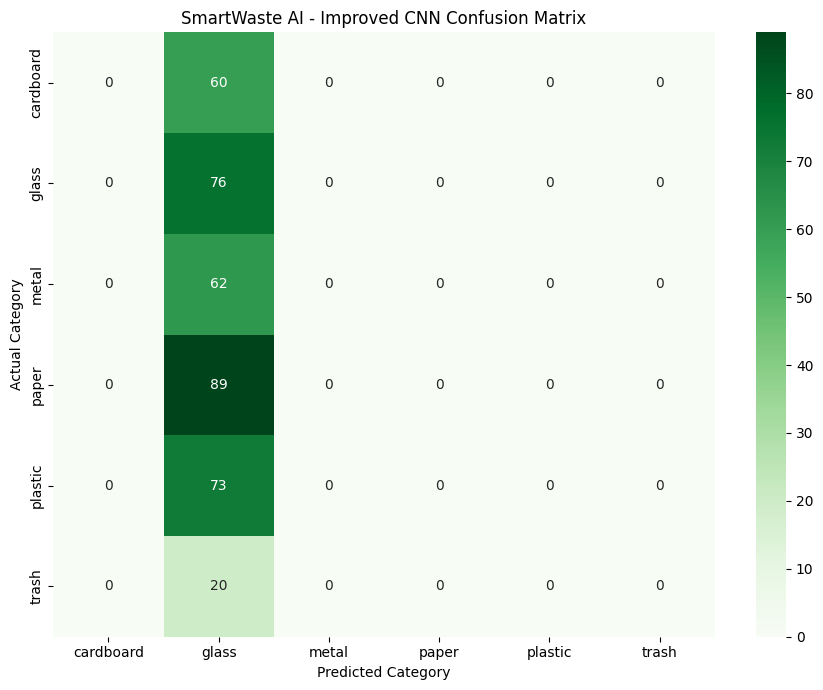

In [13]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - Improved CNN Confusion Matrix")

plt.tight_layout()
plt.show()

FINAL TEST ACCURACY: 20.0 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   cardboard       0.00      0.00      0.00        60
       glass       0.20      1.00      0.33        76
       metal       0.00      0.00      0.00        62
       paper       0.00      0.00      0.00        89
     plastic       0.00      0.00      0.00        73
       trash       0.00      0.00      0.00        20

    accuracy                           0.20       380
   macro avg       0.03      0.17      0.06       380
weighted avg       0.04      0.20      0.07       380



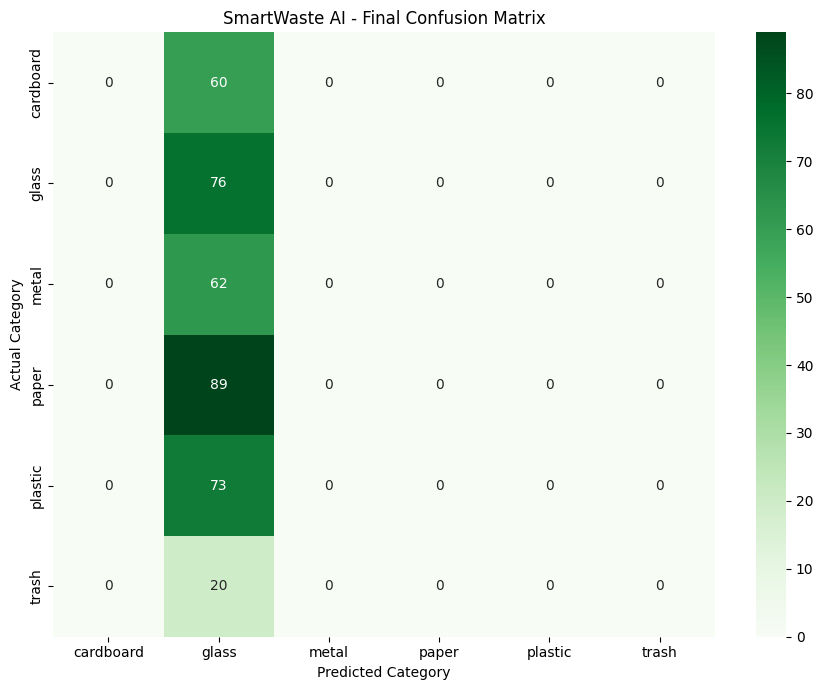

Total test images: 380
Confusion matrix total: 380


In [14]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Generate fresh predictions from the current model
y_true_final = []
y_pred_final = []

for images, labels_batch in test_ds:
    probs = model.predict(images, verbose=0)

    y_true_final.extend(labels_batch.numpy())
    y_pred_final.extend(np.argmax(probs, axis=1))

y_true_final = np.array(y_true_final)
y_pred_final = np.array(y_pred_final)

# Calculate metrics from the same predictions
print("FINAL TEST ACCURACY:",
      round(accuracy_score(y_true_final, y_pred_final)*100, 2), "%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true_final,
    y_pred_final,
    labels=list(range(6)),
    target_names=CLASSES,
    zero_division=0
))

# Generate confusion matrix
cm = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - Final Confusion Matrix")
plt.tight_layout()
plt.show()

print("Total test images:", len(y_true_final))
print("Confusion matrix total:", cm.sum())

In [15]:
# CELL 1: MobileNetV2 Dataset Preparation

import tensorflow as tf
import numpy as np
import os

IMG_SIZE_M = (160, 160)
BATCH_SIZE_M = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_mobilenet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    # Keep pixel values in the 0-255 range.
    # MobileNetV2 preprocessing will happen inside the model.
    image = tf.image.resize(image, IMG_SIZE_M)

    return image, label

def make_mobilenet_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_mobilenet_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        ds = ds.shuffle(
            1000, seed=42, reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE_M).prefetch(AUTOTUNE)

train_ds_m = make_mobilenet_dataset(
    train_paths, train_labels, True
)

val_ds_m = make_mobilenet_dataset(
    val_paths, val_labels
)

test_ds_m = make_mobilenet_dataset(
    test_paths, test_labels
)

print("MobileNetV2 datasets prepared!")
print("Training:", len(train_paths))
print("Validation:", len(val_paths))
print("Testing:", len(test_paths))

MobileNetV2 datasets prepared!
Training: 1768
Validation: 379
Testing: 380


In [16]:
# CELL 2: Load MobileNetV2

from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 pretrained weights loaded!")
print("Base model layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 pretrained weights loaded!
Base model layers: 154


In [17]:
# CELL 3: Build SmartWaste MobileNetV2

inputs = layers.Input(
    shape=(160, 160, 3),
    name="waste_image"
)

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="augmentation")

x = augmentation(inputs)

# MobileNetV2 expects preprocessing to [-1, 1].
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract pretrained visual features.
feature_maps = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(feature_maps)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    6,
    activation="softmax",
    name="waste_predictions"
)(x)

mobilenet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="SmartWaste_MobileNetV2"
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "SmartWaste_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ waste_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ waste_predictions (Dense)       │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
# CELL 4: Stage 1 Training

callbacks_m = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "smartwaste_mobilenet_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_m1 = mobilenet_model.fit(
    train_ds_m,
    validation_data=val_ds_m,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks_m
)

print("MobileNetV2 classification head training completed!")

Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 124ms/step - accuracy: 0.5475 - loss: 1.2696 - val_accuracy: 0.7493 - val_loss: 0.6910 - learning_rate: 0.0010
Epoch 2/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.6974 - loss: 0.8137 - val_accuracy: 0.7678 - val_loss: 0.6096 - learning_rate: 0.0010
Epoch 3/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.7562 - loss: 0.6594 - val_accuracy: 0.7836 - val_loss: 0.5568 - learning_rate: 0.0010
Epoch 4/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.7851 - loss: 0.6143 - val_accuracy: 0.7916 - val_loss: 0.5366 - learning_rate: 0.0010
Epoch 5/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.7896 - loss: 0.5508 - val_accuracy: 0.7942 - val_loss: 0.4865 - learning_rate: 0.0010
Epoch 6/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8235 - loss: 0.4734 - val_accuracy: 0.8153 - val_loss: 0.5138 - learning_rate: 0.0010
Epoch 7/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.8230 - loss: 0.4908 - val_accuracy

In [19]:
# CELL 5: Stage 2 Fine-Tuning

base_model.trainable = True

# Freeze all but the last 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_m2 = mobilenet_model.fit(
    train_ds_m,
    validation_data=val_ds_m,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks_m
)

print("MobileNetV2 fine-tuning completed!")

Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 83ms/step - accuracy: 0.8467 - loss: 0.4130 - val_accuracy: 0.8153 - val_loss: 0.4742 - learning_rate: 1.0000e-05
Epoch 2/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8552 - loss: 0.3773 - val_accuracy: 0.8153 - val_loss: 0.4446 - learning_rate: 1.0000e-05
Epoch 3/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8643 - loss: 0.3476 - val_accuracy: 0.8179 - val_loss: 0.4503 - learning_rate: 1.0000e-05
Epoch 4/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.8829 - loss: 0.3151 - val_accuracy: 0.8153 - val_loss: 0.4524 - learning_rate: 1.0000e-05
Epoch 5/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.8891 - loss: 0.3039 - val_accuracy: 0.8338 - val_loss: 0.4354 - learning_rate: 5.0000e-06
Epoch 6/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.8795 - loss: 0.3163 - val_accuracy: 0.8259 - val_loss: 0.4434 - learning_rate: 5.0000e-06
Epoch 7/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8824 - loss

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.8342 - loss: 0.4665

SMARTWASTE AI - MOBILENETV2 RESULTS
------------------------------------
Test Accuracy: 83.42%
Test Loss: 0.4665

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   cardboard       0.89      0.93      0.91        60
       glass       0.78      0.82      0.79        76
       metal       0.84      0.85      0.85        62
       paper       0.89      0.83      0.86        89
     plastic       0.81      0.82      0.82        73
       trash       0.71      0.60      0.65        20

    accuracy                           0.83       380
   macro avg       0.82      0.81      0.81       380
weighted avg       0.83      0.83      0.83       380



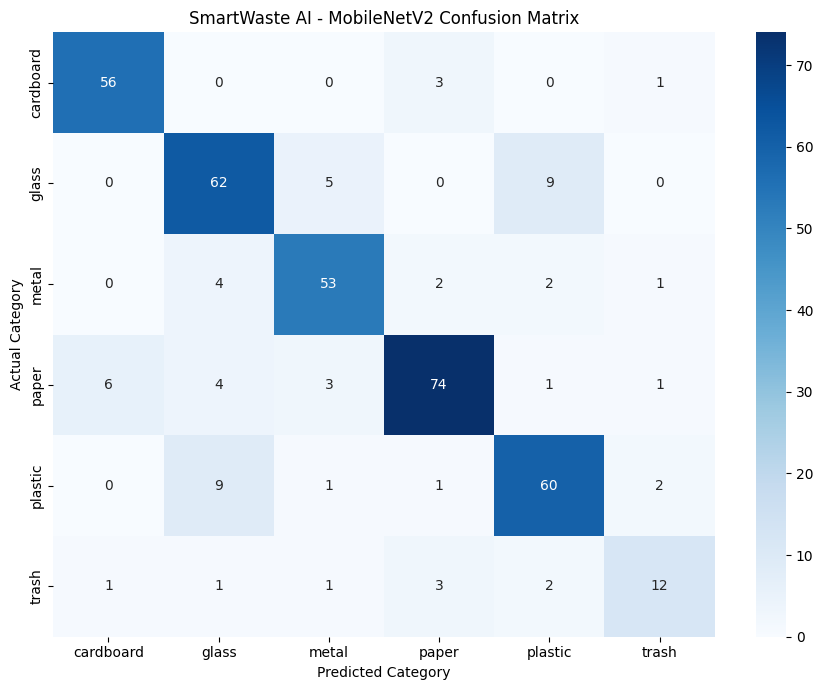

In [20]:
# CELL 6: Final MobileNetV2 Evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

test_loss_m, test_accuracy_m = mobilenet_model.evaluate(
    test_ds_m,
    verbose=1
)

y_true_m = []
y_pred_m = []

for images, labels_batch in test_ds_m:
    probabilities = mobilenet_model.predict(
        images, verbose=0
    )

    y_true_m.extend(labels_batch.numpy())
    y_pred_m.extend(np.argmax(probabilities, axis=1))

y_true_m = np.array(y_true_m)
y_pred_m = np.array(y_pred_m)

print("\nSMARTWASTE AI - MOBILENETV2 RESULTS")
print("------------------------------------")

print(
    f"Test Accuracy: "
    f"{accuracy_score(y_true_m, y_pred_m)*100:.2f}%"
)

print(f"Test Loss: {test_loss_m:.4f}")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true_m,
    y_pred_m,
    labels=list(range(6)),
    target_names=CLASSES,
    zero_division=0
))

cm_m = confusion_matrix(
    y_true_m,
    y_pred_m,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_m,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("SmartWaste AI - MobileNetV2 Confusion Matrix")

plt.tight_layout()
plt.show()

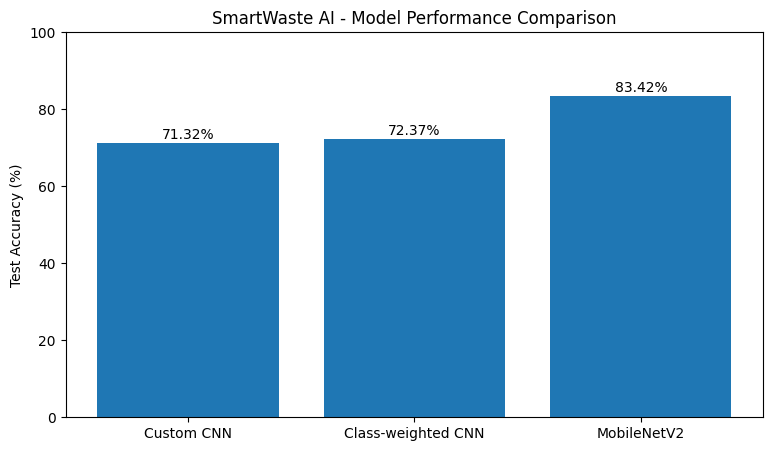

MODEL COMPARISON
Custom CNN: 71.32%
Class-weighted CNN: 72.37%
MobileNetV2: 83.42%


In [21]:
# CELL 7: Model Comparison

custom_cnn_accuracy = 72.37
mobilenet_accuracy = accuracy_score(
    y_true_m, y_pred_m
) * 100

models_names = [
    "Custom CNN",
    "Class-weighted CNN",
    "MobileNetV2"
]

accuracies = [
    71.32,
    custom_cnn_accuracy,
    mobilenet_accuracy
]

plt.figure(figsize=(9, 5))

bars = plt.bar(models_names, accuracies)

plt.ylim(0, 100)
plt.ylabel("Test Accuracy (%)")
plt.title("SmartWaste AI - Model Performance Comparison")

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

print("MODEL COMPARISON")
for name, score in zip(models_names, accuracies):
    print(f"{name}: {score:.2f}%")

In [22]:
# CELL 8: MobileNetV2 Grad-CAM

grad_model_m = tf.keras.Model(
    inputs=inputs,
    outputs=[feature_maps, outputs]
)

def make_gradcam_m(image_array):

    image_array = tf.convert_to_tensor(
        image_array,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_output, predictions = grad_model_m(
            image_array,
            training=False
        )

        class_index = tf.argmax(predictions[0])

        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_output[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / tf.maximum(
        tf.reduce_max(heatmap),
        1e-8
    )

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE_M
    ).numpy().squeeze()

    return heatmap

print("MobileNetV2 Grad-CAM ready!")

MobileNetV2 Grad-CAM ready!


## SmartWaste AI 3.0 — Professional UI
Run this cell after MobileNetV2 training and Grad-CAM setup. It replaces the earlier basic Gradio interface with a dashboard-style application.


In [23]:
# SMARTWASTE AI 3.0 — PROFESSIONAL USER INTERFACE
# Run this cell AFTER the MobileNetV2 model and make_gradcam_m cells.

import gradio as gr
import numpy as np
import cv2
from PIL import Image
from datetime import datetime

# Confirm that the trained model and Grad-CAM function are available.
required_objects = ["mobilenet_model", "make_gradcam_m", "CLASSES", "IMG_SIZE_M"]
missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required project components: " + ", ".join(missing) +
        ". Run the MobileNetV2 training and Grad-CAM cells first."
    )

RECYCLING_GUIDE = {
    "cardboard": "Keep cardboard clean and dry, flatten boxes, and send them to a paper/cardboard recycling collection point.",
    "glass": "Separate glass by local collection rules. Do not mix broken glass with ordinary recyclables unless your local service permits it.",
    "metal": "Empty and rinse metal cans or containers. Separate accepted aluminium and steel items according to local recycling rules.",
    "paper": "Keep paper clean and dry. Remove food-contaminated paper and follow your local paper recycling guidance.",
    "plastic": "Empty and rinse the container, check its resin/recycling acceptance locally, and separate only plastics accepted by your collection service.",
    "trash": "This model classifies the image as general trash. Check local waste rules for safe disposal; some items may require special handling."
}

CATEGORY_EMOJI = {
    "cardboard": "📦", "glass": "🍾", "metal": "🥫",
    "paper": "📄", "plastic": "🧴", "trash": "🗑️"
}

def smartwaste_predict(image, history):
    if image is None:
        raise gr.Error("Please upload a waste image before clicking Classify Waste.")

    try:
        original = image.convert("RGB")
        model_image = original.resize(IMG_SIZE_M)
        batch = np.expand_dims(
            np.asarray(model_image, dtype=np.float32), axis=0
        )

        probabilities = mobilenet_model.predict(batch, verbose=0)[0]
        probabilities = np.asarray(probabilities, dtype=float)

        if len(probabilities) != len(CLASSES):
            raise ValueError("The model output does not match the six configured waste categories.")

        best_index = int(np.argmax(probabilities))
        category = str(CLASSES[best_index]).lower()
        confidence = float(probabilities[best_index])

        # Full probability distribution for the six classes.
        scores = {
            str(CLASSES[i]).capitalize(): float(probabilities[i])
            for i in range(len(CLASSES))
        }

        # MobileNetV2 Grad-CAM heatmap.
        heatmap = make_gradcam_m(batch)
        heatmap = np.asarray(heatmap, dtype=np.float32)
        heatmap = np.nan_to_num(heatmap, nan=0.0, posinf=0.0, neginf=0.0)
        heatmap = cv2.resize(
            heatmap, (model_image.width, model_image.height)
        )
        heatmap = np.clip(heatmap, 0, 1)

        heat_color = cv2.applyColorMap(
            np.uint8(255 * heatmap), cv2.COLORMAP_JET
        )
        heat_color = cv2.cvtColor(heat_color, cv2.COLOR_BGR2RGB)

        original_array = np.asarray(model_image)
        overlay = cv2.addWeighted(
            original_array, 0.60, heat_color, 0.40, 0
        )

        confidence_status = (
            "Low confidence — please verify the material manually."
            if confidence < 0.65
            else "Prediction generated. Please verify before disposal."
        )

        details = f"""
### {CATEGORY_EMOJI.get(category, "♻️")} Prediction: {category.upper()}

**Confidence:** {confidence * 100:.2f}%

**Assessment:** {confidence_status}

### ♻️ Recycling assistant

{RECYCLING_GUIDE.get(category, "Follow local waste-disposal guidance.")}

### About this result

The model selects the category with the highest predicted probability. Grad-CAM highlights image regions that contributed to the model output; it is an explanatory visualization, not proof that the prediction is correct.

*Educational prototype — not a certified waste-sorting or hazardous-material detection system.*
"""

        history = list(history or [])
        timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        history.insert(0, [
            timestamp,
            category.capitalize(),
            f"{confidence * 100:.2f}%"
        ])
        history = history[:20]

        return scores, details, Image.fromarray(overlay), history

    except gr.Error:
        raise
    except Exception as exc:
        raise gr.Error(f"Classification failed: {exc}")

def clear_smartwaste():
    return None, {}, "Upload an image and click **Classify Waste** to see the result.", None, []

CUSTOM_CSS = """
.gradio-container {
    max-width: 1180px !important;
    margin: auto !important;
    background: #f4f8f6 !important;
}
#sw-hero {
    background: linear-gradient(120deg, #102b2a 0%, #145c49 58%, #1b8061 100%);
    color: white;
    padding: 30px 34px;
    border-radius: 20px;
    margin-bottom: 16px;
}
#sw-hero h1 { color: white !important; font-size: 2.25rem !important; margin-bottom: 6px; }
#sw-hero p { color: #d9f4e8 !important; font-size: 1rem; }
.sw-stat {
    background: white;
    border: 1px solid #dce9e2;
    border-radius: 14px;
    padding: 14px;
    text-align: center;
}
.sw-stat strong { display:block; color:#145c49; font-size:1.35rem; }
.sw-stat span { color:#52645b; font-size:.85rem; }
#classify-btn {
    background: #16845d !important;
    color: white !important;
    border: 0 !important;
    font-weight: 700 !important;
}
#clear-btn { border: 1px solid #cbdad2 !important; }
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="emerald",
        secondary_hue="teal",
        neutral_hue="slate"
    ),
    css=CUSTOM_CSS,
    title="SmartWaste AI 3.0"
) as smartwaste_app:

    history_state = gr.State([])

    gr.HTML("""
    <div id="sw-hero">
      <h1>♻️ SmartWaste AI 3.0</h1>
      <p>Intelligent waste classification powered by MobileNetV2 and Explainable AI</p>
      <p>Upload a waste image, inspect the model prediction, and view recycling guidance.</p>
    </div>
    """)

    with gr.Row():
        gr.HTML('<div class="sw-stat"><strong>6</strong><span>Waste categories</span></div>')
        gr.HTML('<div class="sw-stat"><strong>MobileNetV2</strong><span>Transfer learning model</span></div>')
        gr.HTML('<div class="sw-stat"><strong>Grad-CAM</strong><span>Visual explanation</span></div>')
        gr.HTML('<div class="sw-stat"><strong>AI Assistant</strong><span>Recycling guidance</span></div>')

    with gr.Tabs():
        with gr.Tab("🏠 Classify Waste"):
            gr.Markdown("## Waste classification")
            gr.Markdown("Upload a clear image of one waste item. For best results, use a well-lit image with the object clearly visible.")

            with gr.Row(equal_height=False):
                with gr.Column(scale=1):
                    input_image = gr.Image(
                        type="pil",
                        label="Upload waste image",
                        sources=["upload", "webcam"]
                    )
                    with gr.Row():
                        classify_btn = gr.Button(
                            "♻️ Classify Waste",
                            variant="primary",
                            elem_id="classify-btn"
                        )
                        clear_btn = gr.Button(
                            "Clear",
                            variant="secondary",
                            elem_id="clear-btn"
                        )
                    gr.Markdown(
                        "**Supported categories:** Cardboard · Glass · Metal · Paper · Plastic · Trash"
                    )

                with gr.Column(scale=1):
                    prediction_output = gr.Label(
                        num_top_classes=6,
                        label="Model confidence by category"
                    )
                    guidance_output = gr.Markdown(
                        "Upload an image and click **Classify Waste** to see the result."
                    )

            with gr.Row():
                gradcam_output = gr.Image(
                    label="Grad-CAM — regions influencing the prediction",
                    type="pil"
                )

            classify_btn.click(
                fn=smartwaste_predict,
                inputs=[input_image, history_state],
                outputs=[
                    prediction_output,
                    guidance_output,
                    gradcam_output,
                    history_state
                ]
            )

            clear_btn.click(
                fn=clear_smartwaste,
                inputs=[],
                outputs=[
                    input_image,
                    prediction_output,
                    guidance_output,
                    gradcam_output,
                    history_state
                ]
            )

        with gr.Tab("📊 Classification History"):
            gr.Markdown("## Recent predictions")
            gr.Markdown("The latest predictions are kept in this session only. They are not stored in a permanent database.")
            history_table = gr.Dataframe(
                headers=["Timestamp", "Predicted category", "Confidence"],
                datatype=["str", "str", "str"],
                value=[],
                interactive=False,
                label="Session history"
            )
            history_state.change(
                fn=lambda rows: rows,
                inputs=history_state,
                outputs=history_table
            )

        with gr.Tab("♻️ Recycling Guide"):
            gr.Markdown("## Waste sorting guide")
            gr.Markdown("""
| Category | General guidance |
|---|---|
| 📦 Cardboard | Keep dry, flatten boxes, and use accepted cardboard recycling. |
| 🍾 Glass | Separate according to local glass collection rules. |
| 🥫 Metal | Empty and rinse accepted metal containers. |
| 📄 Paper | Keep clean and dry; avoid food-contaminated paper. |
| 🧴 Plastic | Check local acceptance rules and separate accepted plastics. |
| 🗑️ Trash | Follow local general-waste and special-disposal rules. |

**Reminder:** Recycling rules vary by location. Always follow your local waste authority's instructions.
""")

        with gr.Tab("ℹ️ About"):
            gr.Markdown("""
## About SmartWaste AI 3.0

SmartWaste AI is an academic deep-learning prototype that classifies images into six waste categories.

**Technology stack**
- TensorFlow / Keras
- MobileNetV2 transfer learning
- ImageNet pretrained weights
- Grad-CAM explainability
- Gradio user interface

**Important limitations**
- Predictions depend on image quality and similarity to the training dataset.
- A high confidence score does not guarantee a correct prediction.
- The system does not identify hazardous substances or replace professional waste-sorting rules.
- The session history is temporary and clears when the application session ends.
""")

    gr.Markdown(
        "<center>SmartWaste AI 3.0 · Academic project · CNN + MobileNetV2 + Explainable AI</center>"
    )

# Keep the Colab share link active while demonstrating.
smartwaste_app.launch(share=True, show_error=True)


/tmp/ipykernel_786/1261622705.py:155: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://577aee1a11943e42b7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
mobilenet_model.save(
    "/content/SmartWaste_AI_MobileNetV2.keras"
)

print("Model saved successfully!")